# Taller modelos lineales de clasificación - Regresión logística

Sintonice y entrene un modelo de regresión logística para predecir la variable `Churn Label` del dataset **"telco-customer-churn.csv"**, cuya información puede consultar en [IBM](https://community.ibm.com/community/user/businessanalytics/blogs/steven-macko/2019/07/11/telco-customer-churn-1113).

Va a crear un modelo con las siguientes variables:

- Contract
- Dependents
- Online Security
- Tenure Months
- Senior Citizen
- Payment Method
- Internet Service
- Monthly Charges

### Carga y preparación de los datos

In [70]:
from pathlib import Path

import pandas as pd

data_dir = Path().resolve().parent / "data" / "data talleres"
data_name = "Telco_customer_churn.csv"
filepath = data_dir / data_name

df = pd.read_csv(filepath)
df = df.set_index('CustomerID')

variables = [
    'Contract',
    'Dependents',
    'Online Security',
    'Tenure Months',
    'Senior Citizen',
    'Payment Method',
    'Internet Service',
    'Monthly Charges',
    ]
target = 'Churn Label'

df = df[variables + [target]]
df.head()

,Contract,Dependents,Online Security,Tenure Months,Senior Citizen,Payment Method,Internet Service,Monthly Charges,Churn Label
CustomerID,,,,,,,,,
3668-QPYBK,Month-to-month,No,Yes,2,No,Mailed check,DSL,53.85,Yes
9237-HQITU,Month-to-month,Yes,No,2,No,Electronic check,Fiber optic,70.70,Yes
9305-CDSKC,Month-to-month,Yes,No,8,No,Electronic check,Fiber optic,99.65,Yes
7892-POOKP,Month-to-month,Yes,No,28,No,Electronic check,Fiber optic,104.80,Yes
0280-XJGEX,Month-to-month,Yes,No,49,No,Bank transfer (automatic),Fiber optic,103.70,Yes


In [71]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7043 entries, 3668-QPYBK to 3186-AJIEK
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Contract          7043 non-null   object 
 1   Dependents        7043 non-null   object 
 2   Online Security   7043 non-null   object 
 3   Tenure Months     7043 non-null   int64  
 4   Senior Citizen    7043 non-null   object 
 5   Payment Method    7043 non-null   object 
 6   Internet Service  7043 non-null   object 
 7   Monthly Charges   7043 non-null   float64
 8   Churn Label       7043 non-null   object 
dtypes: float64(1), int64(1), object(7)
memory usage: 550.2+ KB


In [72]:
df.describe()

,Tenure Months,Monthly Charges
count,7043.000000,7043.000000
mean,32.371149,64.761692
std,24.559481,30.090047
min,0.000000,18.250000
25%,9.000000,35.500000
50%,29.000000,70.350000
75%,55.000000,89.850000
max,72.000000,118.750000


In [73]:
df.isna().sum()

Contract            0
Dependents          0
Online Security     0
Tenure Months       0
Senior Citizen      0
Payment Method      0
Internet Service    0
Monthly Charges     0
Churn Label         0
dtype: int64

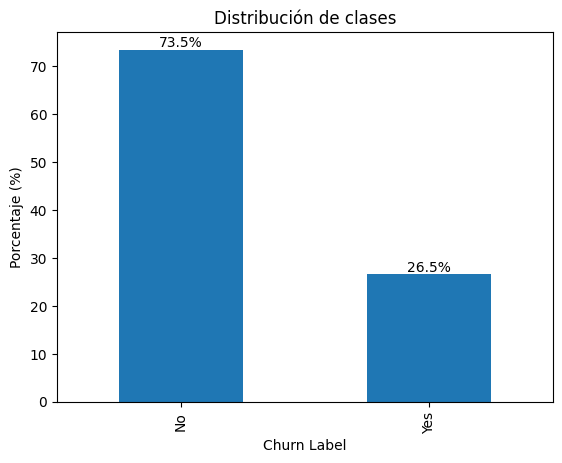

In [74]:
ax = (df[target].value_counts(normalize=True) * 100).plot(
    kind='bar', 
    title='Distribución de clases'
)

ax.bar_label(ax.containers[0], fmt='%.1f%%')
ax.set_ylabel('Porcentaje (%)');

Las clases están desbalanceadas: aproximadamente el 26.5 % de los clientes se retiran (`Yes`) y el 73.5 % no (`No`).

In [75]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

X = df.drop(target, axis=1)
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    stratify=y,
    random_state=72,
    train_size=0.7
    )

print(f'Tamaño del conjunto de entrenamiento es: {X_train.shape}')
print(f'Tamaño del conjunto de prueba es: {X_test.shape}')

# Codificación de variable a predecir: No -> 0, Yes -> 1
le = LabelEncoder()
y_train = le.fit_transform(y_train)
y_test = le.transform(y_test)
le.classes_

Tamaño del conjunto de entrenamiento es: (4930, 8)
Tamaño del conjunto de prueba es: (2113, 8)


array(['No', 'Yes'], dtype=object)

In [76]:
import warnings

warnings.filterwarnings("ignore")

## Modelo 1

Debe usar `Pipeline` y `ColumnTransformer` para crear un flujo que integre el procesamiento de los datos y el modelado, de manera que evite la fuga de datos.

El procesamiento de los datos debe incluir las siguientes transformaciones:

- Estandarización de variables numéricas
- Imputación de datos nulos
- Codificación de variables categóricas

Escoja una métrica que priorice la clasificación correcta de los clientes que se retiran. Con esta métrica sintonice `C` y `l1_ratio`.

Reporte:

- los resultados de las métricas de validación, entrenamiento y prueba.
- los valores de los hiperparámetros sintonizados.
- la matriz de confusión.
- el reporte de clasificación.

Analice los resultados obtenidos. Responda las siguientes preguntas:

- ¿El modelo es funcional?
- ¿El modelo esta correctamente ajustado, o está sobreajustado o subajustado? 
- ¿El modelo está balanceado? ¿Con qué clase tiene mejor desempeño?

Sí el modelo no está balanceado intente balancearlo.

Reporte los coeficientes de este último modelo. ¿Cuáles son las 5 características más importantes de su modelo?

In [77]:
#pipeline de preprocesamiento y modelo

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

numericas = ['Tenure Months', 'Monthly Charges']
categoricas = [
    'Contract',
    'Dependents',
    'Online Security',
    'Senior Citizen',
    'Payment Method',
    'Internet Service',
    ]

num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(drop='if_binary', handle_unknown='ignore'))
])

preprocesamiento = ColumnTransformer([
    ('num', num_pipeline, numericas),
    ('cat', cat_pipeline, categoricas)
])

pipeline = Pipeline([
    ('preprocesamiento', preprocesamiento),
    ('logistic', LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        max_iter=5000,
        random_state=72
        ))
])

pipeline

,steps,"[('preprocesamiento', ...), ('logistic', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


**Nota sobre `Contract`:** aunque tiene un orden (mes a mes < un año < dos años), se codificó con one-hot y no como ordinal. Usando la codificación ordinal nos obliga a un solo coeficiente. Con one-hot cada tipo de contrato tiene su propio peso. Se probó la versión con Contract ordinal y el modelo balanceado terminaba con una regularización Lasso muy fuerte, conservaba solo 3 variables y aumentaba los falsos positivos (0.69 frente a 0.75).

Como se quiere priorizar la clasificación correcta de los clientes que **se retiran** (clase positiva `Yes`), la métrica escogida es el **recall** de la clase `Yes`: la proporción de clientes que realmente se retiran que el modelo logra identificar. Con ella se sintonizan `C` y `l1_ratio`.

In [78]:
import numpy as np
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GridSearchCV

grid = {
    'logistic__C': np.logspace(-3, 3, 20),
    'logistic__l1_ratio': [0, 0.1, 0.25, 0.5, 0.75, 0.9, 1]
    }

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=grid,
    scoring='recall',
    cv=5,
    n_jobs=-1
    )

grid_search.fit(X_train, y_train)

,estimator,Pipeline(step...ver='saga'))])
,param_grid,"{'logistic__C': array([1.0000...00000000e+03]), 'logistic__l1_ratio': [0, 0.1, ...]}"
,scoring,'recall'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [79]:
print(f'Cross-validation score: {grid_search.best_score_:.3f}')
print(f'Best hyperparameters: {grid_search.best_params_}')
print(f'Train score: {grid_search.score(X_train, y_train):.3f}')
print(f'Test score: {grid_search.score(X_test, y_test):.3f}')

Cross-validation score: 0.551
Best hyperparameters: {'logistic__C': np.float64(1.438449888287663), 'logistic__l1_ratio': 0}
Train score: 0.550
Test score: 0.553


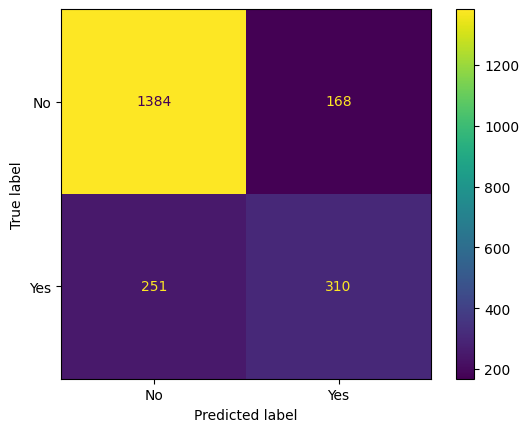

In [80]:
ConfusionMatrixDisplay.from_estimator(
    grid_search.best_estimator_,
    X_test,
    y_test,
    display_labels=le.classes_
    );

In [81]:
print(classification_report(
    y_test,
    grid_search.best_estimator_.predict(X_test),
    target_names=le.classes_
    ))

              precision    recall  f1-score   support

          No       0.85      0.89      0.87      1552
         Yes       0.65      0.55      0.60       561

    accuracy                           0.80      2113
   macro avg       0.75      0.72      0.73      2113
weighted avg       0.79      0.80      0.80      2113



### Análisis del Modelo 1 (sin balancear)

Métrica (recall `Yes`)

* Validación (CV) -> 0.551
* Entrenamiento -> 0.550
* Prueba -> 0.553

Hiperparámetros sintonizados: `C ≈ 1.438`, `l1_ratio = 0` (regularización tipo Ridge, L2).

Matriz de confusión en prueba: de 561 clientes que se retiraron, el modelo detecta 310 y se le escapan 251. De 1552 clientes que no se retiraron, clasifica bien 1384.

**¿El modelo es funcional?** Parcialmente poeque la exactitud es de 0.80, pero solo identifica el 55% de los clientes que se retiran, que es justamente la clase que se quiere priorizar. Casi la mitad de los retiros pasarían desapercibidos.

**¿Está bien ajustado?** Sí porque los valores de validación, entrenamiento y prueba son prácticamente iguales (≈0.55), así que no hay sobreajuste. El desempeño bajo en la clase `Yes` se debe más al desbalance de clases y a las pocas variables usadas que a un subajuste por exceso de regularización (el `C` escogido es moderado).

**¿Está balanceado?** No porque tiene mejor desempeño con la clase `No` (recall 0.89, f1 0.87) que con la clase `Yes` (recall 0.55, f1 0.60). Esto se explica porque solo el 26.5 % de los clientes se retiran, por eso se intenta balancear el modelo.

### Modelo 1 balanceado

Se usa la ponderación de clases (`class_weight='balanced'`) para que los errores en la clase minoritaria (`Yes`) pesen más en la función de pérdida.

In [82]:
pipeline_bal = Pipeline([
    ('preprocesamiento', preprocesamiento),
    ('logistic', LogisticRegression(
        penalty='elasticnet',
        solver='saga',
        max_iter=5000,
        random_state=72,
        class_weight='balanced'
        ))
])

grid_search_bal = GridSearchCV(
    estimator=pipeline_bal,
    param_grid=grid,
    scoring='recall',
    cv=5,
    n_jobs=-1
    )

grid_search_bal.fit(X_train, y_train)

,estimator,Pipeline(step...ver='saga'))])
,param_grid,"{'logistic__C': array([1.0000...00000000e+03]), 'logistic__l1_ratio': [0, 0.1, ...]}"
,scoring,'recall'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [83]:
print(f'Cross-validation score: {grid_search_bal.best_score_:.3f}')
print(f'Best hyperparameters: {grid_search_bal.best_params_}')
print(f'Train score: {grid_search_bal.score(X_train, y_train):.3f}')
print(f'Test score: {grid_search_bal.score(X_test, y_test):.3f}')

Cross-validation score: 0.794
Best hyperparameters: {'logistic__C': np.float64(0.3359818286283781), 'logistic__l1_ratio': 0}
Train score: 0.796
Test score: 0.809


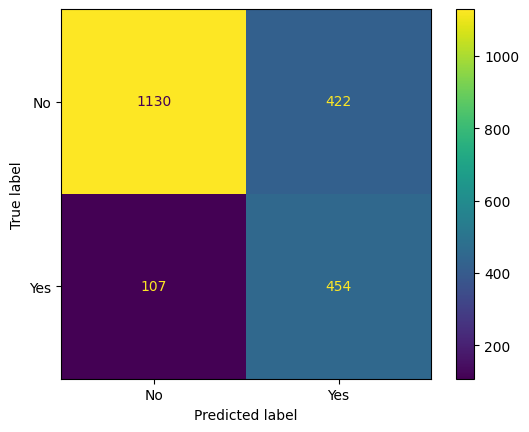

In [84]:
ConfusionMatrixDisplay.from_estimator(
    grid_search_bal.best_estimator_,
    X_test,
    y_test,
    display_labels=le.classes_
    );

In [85]:
print(classification_report(
    y_test,
    grid_search_bal.best_estimator_.predict(X_test),
    target_names=le.classes_
    ))

              precision    recall  f1-score   support

          No       0.91      0.73      0.81      1552
         Yes       0.52      0.81      0.63       561

    accuracy                           0.75      2113
   macro avg       0.72      0.77      0.72      2113
weighted avg       0.81      0.75      0.76      2113



In [86]:
best_estimator = grid_search_bal.best_estimator_

pesos = pd.DataFrame(
    data=best_estimator.named_steps['logistic'].coef_,
    columns=best_estimator.named_steps['preprocesamiento'].get_feature_names_out(),
    index=['Pesos']
    )

pesos['intercept'] = best_estimator.named_steps['logistic'].intercept_
pesos = pesos.T.sort_values('Pesos', ascending=False)
pesos

,Pesos
cat__Contract_Month-to-month,0.755257
cat__Internet Service_Fiber optic,0.444500
cat__Online Security_No,0.369290
cat__Payment Method_Electronic check,0.269738
num__Monthly Charges,0.265457
cat__Senior Citizen_Yes,0.248671
cat__Contract_One year,-0.008707
cat__Payment Method_Credit card (automatic),-0.029381
cat__Online Security_Yes,-0.110829
cat__Payment Method_Mailed check,-0.114894


In [87]:
# Las 5 características más importantes (mayor peso en valor absoluto, sin el intercepto)
pesos.drop('intercept').reindex(
    pesos.drop('intercept')['Pesos'].abs().sort_values(ascending=False).index
    ).head(5)

,Pesos
cat__Dependents_Yes,-1.513391
cat__Contract_Month-to-month,0.755257
cat__Contract_Two year,-0.749189
num__Tenure Months,-0.700717
cat__Internet Service_Fiber optic,0.444500


### Análisis del Modelo 1 balanceado

Métrica (recall `Yes`)

* Validación (CV)
  - Sin balancear: 0.551
  - Balanceado: 0.794

* Entrenamiento
  - Sin balancear: 0.550
  - Balanceado: 0.796

* Prueba
  - Sin balancear: 0.553
  - Balanceado: 0.809

Hiperparámetros sintonizados: `C ≈ 0.336`, `l1_ratio = 0` (L2), `class_weight='balanced'`.

Matriz de confusión en prueba: ahora detecta 454 de los 561 clientes que se retiran (solo se escapan 107). Pero umentan los falsos positivos: 422 clientes que no se retiran se marcan como posibles retiros.

- **Funcional:** sí, para el objetivo planteado. Identifica el 81 % de los clientes que se retiran. La precisión de `Yes` (0.52) indica que aproximadamente la mitad de las alertas son falsas, lo cual suele ser aceptable en retención, porque una campaña para un cliente que no se iba a ir cuesta menos que perder un cliente.
- **Ajuste:** correcto. Validación (0.794), entrenamiento (0.796) y prueba (0.809) son muy similares, así que no hay sobreajuste ni subajuste.
- **Balance:** mucho más balanceado. El recall es 0.73 para `No` y 0.81 para `Yes`, y el macro recall sube de 0.72 a 0.77. Ahora tiene mejor recall con la clase `Yes`, aunque en f1 sigue siendo mejor con la clase `No` (0.81 frente a 0.63). La exactitud baja de 0.80 a 0.75, que es el costo esperado de balancear.

**Coeficientes y 5 características más importantes.** Como las variables numéricas están estandarizadas y las categóricas son 0/1, la magnitud de los pesos sirve como medida aproximada de importancia:

1. `Dependents_Yes` (−1.51): tener dependientes reduce fuertemente la probabilidad de retiro.
2. `Contract_Month-to-month` (+0.76): el contrato mes a mes aumenta la probabilidad de retiro.
3. `Contract_Two year` (−0.75): el contrato a dos años la reduce.
4. `Tenure Months` (−0.70): a mayor antigüedad, menor probabilidad de retiro.
5. `Internet Service_Fiber optic` (+0.44): los clientes con fibra óptica se retiran más.

Le siguen `Online Security_No` (+0.37), `Payment Method_Electronic check` (+0.27) y `Monthly Charges` (+0.27).

## Modelo 2

Vuelva a entrenar y sintonizar el modelo, pero ahora seleccione una métrica que priorice etiquetar correctamente a los clientes que no se han retirado.

Reporte:

- los resultados de las métricas de validación, entrenamiento y prueba.
- los valores de los hiperparámetros sintonizados.
- la matriz de confusión.
- el reporte de clasificación.

Analice los resultados obtenidos. 
- ¿El modelo es funcional?
- ¿El modelo esta correctamente ajustado, o está sobreajustado o subajustado? 
- ¿El modelo está balanceado? ¿Con qué clase tiene mejor desempeño?

Reporte los coeficientes de este último modelo. ¿Cuáles son las 5 características más importantes de su modelo?


Ahora se quiere priorizar etiquetar correctamente a los clientes que **no se han retirado** (clase `No`, codificada como 0). La métrica escogida es el **recall de la clase `No`** (especificidad), que se construye con `make_scorer` indicando `pos_label=0`.

In [88]:
from sklearn.metrics import make_scorer, recall_score

scorer = make_scorer(recall_score, pos_label=0)

grid_search_2 = GridSearchCV(
    estimator=pipeline,
    param_grid=grid,
    scoring=scorer,
    cv=5,
    n_jobs=-1
    )

grid_search_2.fit(X_train, y_train)

,estimator,Pipeline(step...ver='saga'))])
,param_grid,"{'logistic__C': array([1.0000...00000000e+03]), 'logistic__l1_ratio': [0, 0.1, ...]}"
,scoring,"make_scorer(r..., pos_label=0)"
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [89]:
print(f'Cross-validation score: {grid_search_2.best_score_:.3f}')
print(f'Best hyperparameters: {grid_search_2.best_params_}')
print(f'Train score: {grid_search_2.score(X_train, y_train):.3f}')
print(f'Test score: {grid_search_2.score(X_test, y_test):.3f}')

Cross-validation score: 1.000
Best hyperparameters: {'logistic__C': np.float64(0.001), 'logistic__l1_ratio': 0}
Train score: 0.995
Test score: 0.995


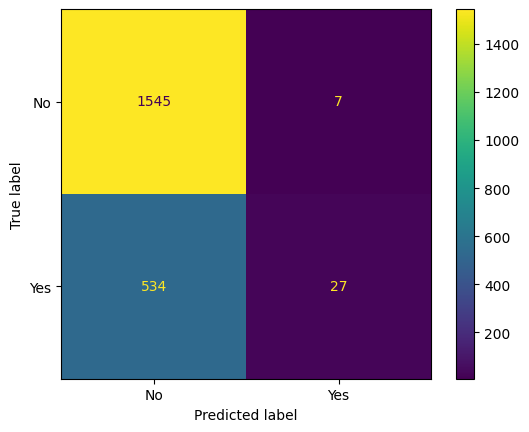

In [90]:
ConfusionMatrixDisplay.from_estimator(
    grid_search_2.best_estimator_,
    X_test,
    y_test,
    display_labels=le.classes_
    );

In [91]:
print(classification_report(
    y_test,
    grid_search_2.best_estimator_.predict(X_test),
    target_names=le.classes_
    ))

              precision    recall  f1-score   support

          No       0.74      1.00      0.85      1552
         Yes       0.79      0.05      0.09       561

    accuracy                           0.74      2113
   macro avg       0.77      0.52      0.47      2113
weighted avg       0.76      0.74      0.65      2113



In [92]:
best_estimator = grid_search_2.best_estimator_

pesos = pd.DataFrame(
    data=best_estimator.named_steps['logistic'].coef_,
    columns=best_estimator.named_steps['preprocesamiento'].get_feature_names_out(),
    index=['Pesos']
    )

pesos['intercept'] = best_estimator.named_steps['logistic'].intercept_
pesos = pesos.T.sort_values('Pesos', ascending=False)
pesos

,Pesos
cat__Contract_Month-to-month,0.209403
num__Monthly Charges,0.178320
cat__Online Security_No,0.172551
cat__Internet Service_Fiber optic,0.158342
cat__Payment Method_Electronic check,0.146236
cat__Senior Citizen_Yes,0.070536
cat__Payment Method_Mailed check,-0.046662
cat__Payment Method_Credit card (automatic),-0.048529
cat__Payment Method_Bank transfer (automatic),-0.051062
cat__Internet Service_DSL,-0.071564


In [93]:
# Las 5 características más importantes (mayor peso en valor absoluto, sin el intercepto)
pesos.drop('intercept').reindex(
    pesos.drop('intercept')['Pesos'].abs().sort_values(ascending=False).index
    ).head(5)

,Pesos
num__Tenure Months,-0.349898
cat__Contract_Month-to-month,0.209403
num__Monthly Charges,0.178320
cat__Online Security_No,0.172551
cat__Internet Service_Fiber optic,0.158342


### Análisis del Modelo 2


Métrica (recall `No`)

* Validación (CV): 1.000
* Entrenamiento: 0.995
* Prueba: 0.995

Hiperparámetros sintonizados: `C = 0.001` (el valor más pequeño de la grilla, es decir, la regularización máxima) y `l1_ratio = 0`.

Matriz de confusión en prueba: 1545 de 1552 clientes que no se retiran se clasifican bien, pero solo se detectan 27 de los 561 que se retiran.

**¿El modelo es funcional?** No. Al optimizar solo el recall de la clase `No`, la búsqueda escoge la regularización máxima, que deja los coeficientes casi en cero. Así el modelo termina prediciendo prácticamente siempre la clase mayoritaria (`No`). Su exactitud (0.74) es casi igual a la de un modelo trivial que siempre dijera `No` (0.735), y la métrica aparentemente perfecta (0.995) es engañosa. Esto muestra que una métrica que solo mira una clase puede ser maximizada por un modelo degenerado.

**¿Está bien ajustado?** Está **subajustado**. No hay diferencia entre entrenamiento, validación y prueba, pero la regularización extrema (`C = 0.001`) le impide aprender la relación entre las variables y el retiro.

**¿Está balanceado?** No, está totalmente desbalanceado a favor de la clase `No`: recall 1.00 y f1 0.85 para `No`, frente a recall 0.05 y f1 0.09 para `Yes`. El macro recall es 0.52, casi igual al de adivinar.

**Coeficientes y 5 características más importantes.** Todos los pesos son pequeños por la fuerte regularización, pero el orden de importancia es coherente con el Modelo 1:

1. `Tenure Months` (−0.35)
2. `Contract_Month-to-month` (+0.21)
3. `Monthly Charges` (+0.18)
4. `Online Security_No` (+0.17)
5. `Internet Service_Fiber optic` (+0.16)

Si en la práctica se quisiera priorizar a los clientes que no se retiran sin obtener un modelo trivial, convendría usar una métrica como la precisión de la clase `No`, el f1 macro o el `balanced_accuracy`, en lugar del recall de una sola clase.